In [ ]:
##Importación de librerias

In [78]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import warnings
warnings.filterwarnings("ignore") 
from scipy.stats import zscore


In [ ]:
#Crear carpeta para las imágenes

In [19]:
os.makedirs("Graficas_EDA", exist_ok=True)

In [ ]:
#Carga de datos 

In [20]:
fact = pd.read_csv('FACT_SALES (1).csv')
producto = pd.read_excel('DIM_PRODUCT (1).xlsx')
categoria = pd.read_csv('DIM_CATEGORY (2).csv')
print("\n Archivos cargados correctamente.\n")


 Archivos cargados correctamente.



In [ ]:
# Dimensiones

In [21]:
print("FACT_SALES")
print(fact.shape)

print()

print("DIM_PRODUCT")
print(producto.shape)

print()

print("DIM_CATEGORY")
print(categoria.shape)

FACT_SALES
(122002, 6)

DIM_PRODUCT
(505, 9)

DIM_CATEGORY
(5, 2)


In [ ]:
#Primeras filas

In [22]:
print("FACT SALES")
display(fact.head())

print()

print("DIM PRODUCT")
display(producto.head())

print()

print("DIM CATEGORY")
display(categoria.head())

FACT SALES


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5



DIM PRODUCT


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO



DIM CATEGORY


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


In [ ]:
# Informacion general

In [23]:
print("FACT SALES")
fact.info()

print()

print("DIM PRODUCT")
producto.info()

print()

print("DIM CATEGORY")
categoria.info()

FACT SALES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122002 entries, 0 to 122001
Data columns (total 6 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   WEEK                         122002 non-null  object 
 1   ITEM_CODE                    122002 non-null  object 
 2   TOTAL_UNIT_SALES             122002 non-null  float64
 3   TOTAL_VALUE_SALES            122002 non-null  float64
 4   TOTAL_UNIT_AVG_WEEKLY_SALES  122002 non-null  float64
 5   REGION                       122002 non-null  object 
dtypes: float64(3), object(3)
memory usage: 5.6+ MB

DIM PRODUCT
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505 entries, 0 to 504
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   MANUFACTURER      505 non-null    object
 1   BRAND             505 non-null    object
 2   ITEM              503 non-null    object
 3   ITE

In [ ]:
#Columnas

In [24]:
print("FACT SALES")

for columna in fact.columns:
    print(columna)

print()

print("DIM PRODUCT")

for columna in producto.columns:
    print(columna)

print()

print("DIM CATEGORY")

for columna in categoria.columns:
    print(columna)

FACT SALES
WEEK
ITEM_CODE
TOTAL_UNIT_SALES
TOTAL_VALUE_SALES
TOTAL_UNIT_AVG_WEEKLY_SALES
REGION

DIM PRODUCT
MANUFACTURER
BRAND
ITEM
ITEM_DESCRIPTION
CATEGORY
FORMAT
ATTR1
ATTR2
ATTR3

DIM CATEGORY
ID_CATEGORY
CATEGORY


In [ ]:
# Tipos de datos

In [25]:
print(fact.dtypes)

print()

print(producto.dtypes)

print()

print(categoria.dtypes)

WEEK                            object
ITEM_CODE                       object
TOTAL_UNIT_SALES               float64
TOTAL_VALUE_SALES              float64
TOTAL_UNIT_AVG_WEEKLY_SALES    float64
REGION                          object
dtype: object

MANUFACTURER        object
BRAND               object
ITEM                object
ITEM_DESCRIPTION    object
CATEGORY             int64
FORMAT              object
ATTR1               object
ATTR2               object
ATTR3               object
dtype: object

ID_CATEGORY     int64
CATEGORY       object
dtype: object


In [ ]:
# Valores nulos

In [26]:
print("FACT SALES")

print(fact.isnull().sum())

print()

print("DIM PRODUCT")

print(producto.isnull().sum())

print()

print("DIM CATEGORY")

print(categoria.isnull().sum())

FACT SALES
WEEK                           0
ITEM_CODE                      0
TOTAL_UNIT_SALES               0
TOTAL_VALUE_SALES              0
TOTAL_UNIT_AVG_WEEKLY_SALES    0
REGION                         0
dtype: int64

DIM PRODUCT
MANUFACTURER        0
BRAND               0
ITEM                2
ITEM_DESCRIPTION    0
CATEGORY            0
FORMAT              0
ATTR1               6
ATTR2               0
ATTR3               6
dtype: int64

DIM CATEGORY
ID_CATEGORY    0
CATEGORY       0
dtype: int64


In [ ]:
# Porcentaje de valores nulos

In [27]:
def porcentaje_nulos(df):

    nulos = df.isnull().sum()

    porcentaje = (nulos / len(df))*100

    reporte = pd.DataFrame({

        "Nulos":nulos,
        "Porcentaje":porcentaje

    })

    return reporte.sort_values(
        by="Porcentaje",
        ascending=False
    )

print("FACT SALES")

display(
    porcentaje_nulos(fact)
)

print()

print("DIM PRODUCT")

display(
    porcentaje_nulos(producto)
)

print()

print("DIM CATEGORY")

display(
    porcentaje_nulos(categoria)
)

FACT SALES


,Nulos,Porcentaje
WEEK,0,0.0
ITEM_CODE,0,0.0
TOTAL_UNIT_SALES,0,0.0
TOTAL_VALUE_SALES,0,0.0
TOTAL_UNIT_AVG_WEEKLY_SALES,0,0.0
REGION,0,0.0



DIM PRODUCT


,Nulos,Porcentaje
ATTR1,6,1.188119
ATTR3,6,1.188119
ITEM,2,0.396040
MANUFACTURER,0,0.000000
BRAND,0,0.000000
ITEM_DESCRIPTION,0,0.000000
CATEGORY,0,0.000000
FORMAT,0,0.000000
ATTR2,0,0.000000



DIM CATEGORY


,Nulos,Porcentaje
ID_CATEGORY,0,0.0
CATEGORY,0,0.0


In [ ]:
# Registros duplicados

In [28]:

print("FACT SALES")

print(
    fact.duplicated().sum()
)

print()

print("DIM PRODUCT")

print(
    producto.duplicated().sum()
)

print()

print("DIM CATEGORY")

print(
    categoria.duplicated().sum()
)

FACT SALES
0

DIM PRODUCT
0

DIM CATEGORY
0


In [ ]:
# Estadisticas descriptivas

In [29]:
display(
    fact.describe().T
)

,count,mean,std,min,25%,50%,75%,max
TOTAL_UNIT_SALES,122002.0,3.211097,14.496009,0.000,0.063,0.3670,1.5200,504.681
TOTAL_VALUE_SALES,122002.0,90.513761,350.236505,0.001,2.662,16.8120,62.9615,12236.759
TOTAL_UNIT_AVG_WEEKLY_SALES,122002.0,10.099904,22.650142,0.042,2.316,3.9935,8.8980,794.000


In [ ]:
# Variables numéricas

In [30]:
variables_numericas = fact.select_dtypes(
    include=np.number
)

print(variables_numericas.columns.tolist())

['TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES']


In [ ]:
# Variables categóricas

In [31]:
variables_categoricas = fact.select_dtypes(
    include="object"
)

print(
    variables_categoricas.columns.tolist()
)

['WEEK', 'ITEM_CODE', 'REGION']


In [ ]:
# Valores únicos

In [32]:
for columna in fact.columns:

    print()

    print(columna)

    print(
        fact[columna].nunique()
    )


WEEK
80

ITEM_CODE
350

TOTAL_UNIT_SALES
15197

TOTAL_VALUE_SALES
64425

TOTAL_UNIT_AVG_WEEKLY_SALES
26662

REGION
7


In [ ]:
# Frecuencia de regiones

In [33]:
display(

    fact["REGION"]

    .value_counts()

)

REGION
TOTAL AUTOS SCANNING MEXICO    20990
TOTAL AUTOS AREA 2             18505
TOTAL AUTOS AREA 4             17182
TOTAL AUTOS AREA 6             16913
TOTAL AUTOS AREA 3             16496
TOTAL AUTOS AREA 5             16135
TOTAL AUTOS AREA 1             15781
Name: count, dtype: int64

In [ ]:
# Top productos

In [34]:
display(

fact["ITEM_CODE"]

.value_counts()

.head(20)

)

ITEM_CODE
7501025405106    560
7501025405885    560
4008455425412    560
7501025401849    560
7501025401856    560
7501025401917    560
7501025401894    560
7501025401900    560
7501025401801    560
7702137007152    560
7501025405090    560
7501025401795    560
7501025405212    560
7501021160719    560
7501681100421    560
7501681100674    560
7702137007169    560
7501058796585    560
7501681100292    560
7501058716088    560
Name: count, dtype: int64

In [ ]:
# Calidad de los datos

In [35]:
reporte = pd.DataFrame({

    "Variable":fact.columns,

    "Tipo":

    fact.dtypes.values,

    "Nulos":

    fact.isnull().sum().values,

    "Valores Únicos":

    [fact[col].nunique()

     for col in fact.columns]

})

display(reporte)

,Variable,Tipo,Nulos,Valores Únicos
0,WEEK,object,0,80
1,ITEM_CODE,object,0,350
2,TOTAL_UNIT_SALES,float64,0,15197
3,TOTAL_VALUE_SALES,float64,0,64425
4,TOTAL_UNIT_AVG_WEEKLY_SALES,float64,0,26662
5,REGION,object,0,7


In [ ]:
#Exportar reporte

In [36]:
reporte.to_csv(

    "Reporte_Calidad_Datos.csv",

    index=False,

    encoding="utf-8-sig"

)

print("Reporte exportado correctamente.")

Reporte exportado correctamente.


In [ ]:
# Histograma de ventas unitarias

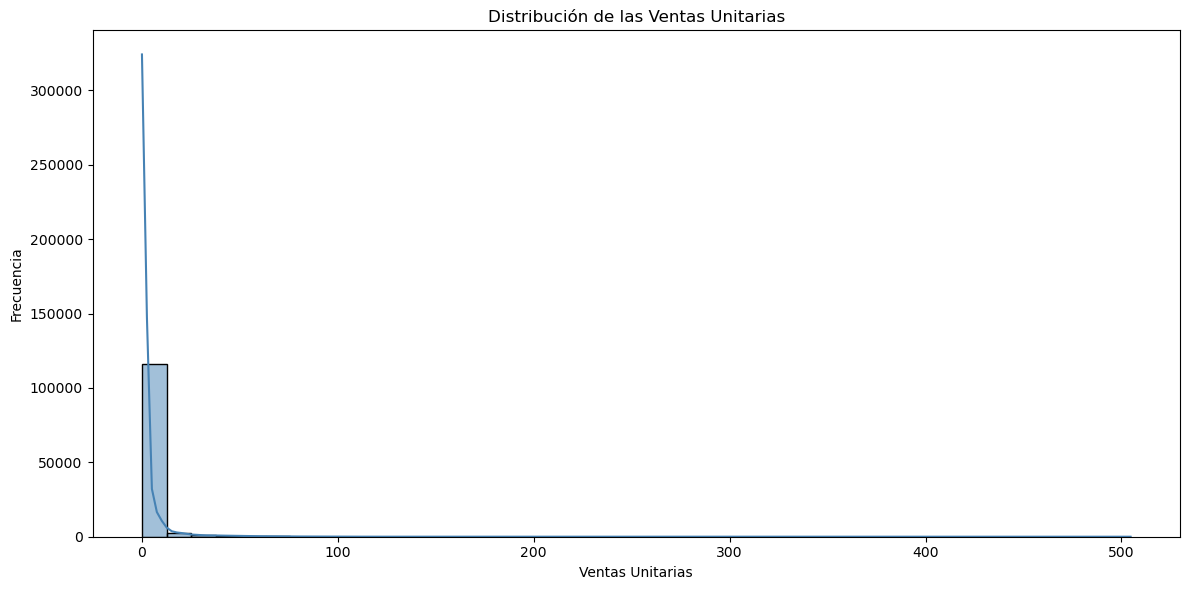

In [37]:
plt.figure(figsize=(12,6))

sns.histplot(
    data=fact,
    x="TOTAL_UNIT_SALES",
    bins=40,
    kde=True,
    color="steelblue"
)

plt.title("Distribución de las Ventas Unitarias")

plt.xlabel("Ventas Unitarias")

plt.ylabel("Frecuencia")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/01_Histograma_Ventas_Unitarias.png",
    dpi=300
)

plt.show()

In [ ]:
# Histograma Total de ventas

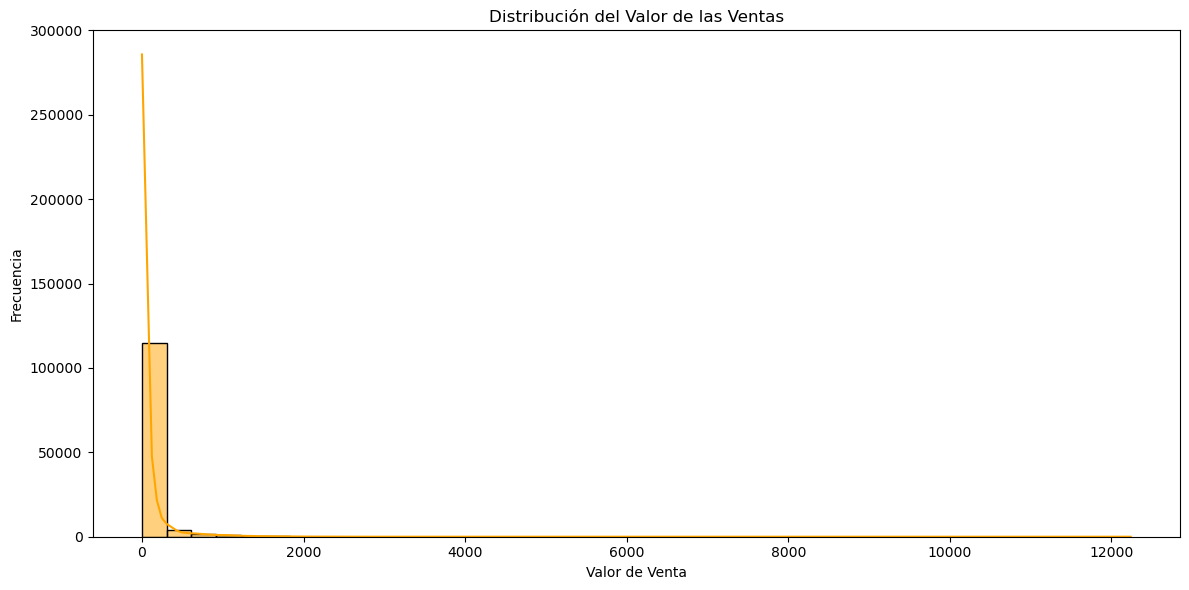

In [38]:
plt.figure(figsize=(12,6))

sns.histplot(
    data=fact,
    x="TOTAL_VALUE_SALES",
    bins=40,
    kde=True,
    color="orange"
)

plt.title("Distribución del Valor de las Ventas")

plt.xlabel("Valor de Venta")

plt.ylabel("Frecuencia")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/02_Histograma_Valor_Ventas.png",
    dpi=300
)

plt.show()

In [ ]:
# Histograma por region

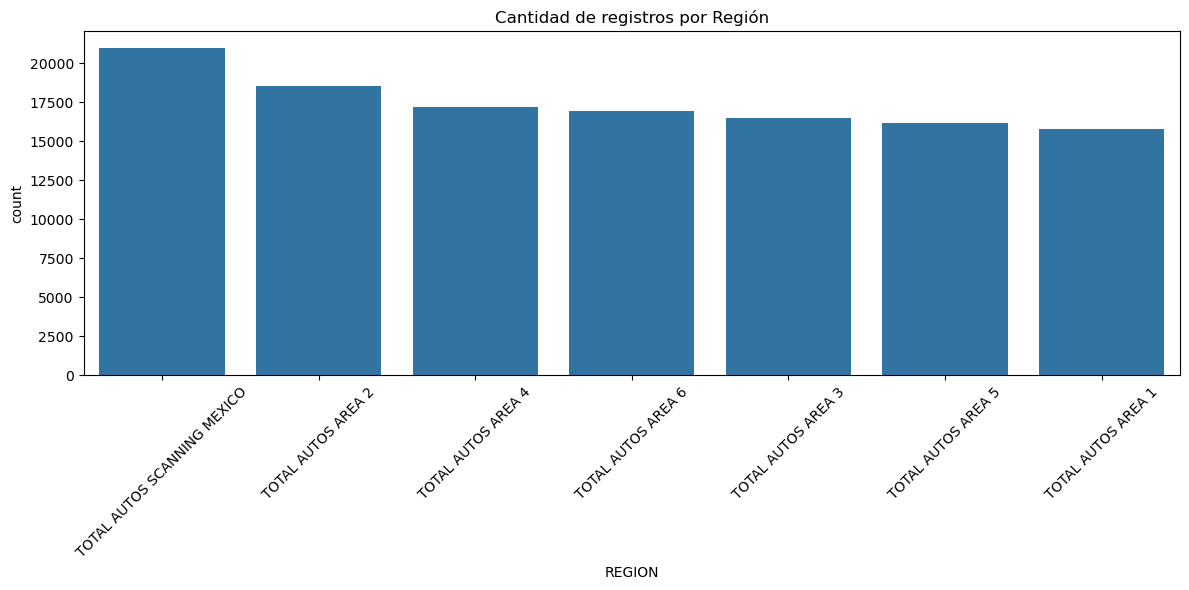

In [39]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=fact,
    x="REGION",
    order=fact["REGION"].value_counts().index
)

plt.xticks(rotation=45)

plt.title("Cantidad de registros por Región")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/03_Regiones.png",
    dpi=300
)

plt.show()

In [ ]:
# Boxplot general

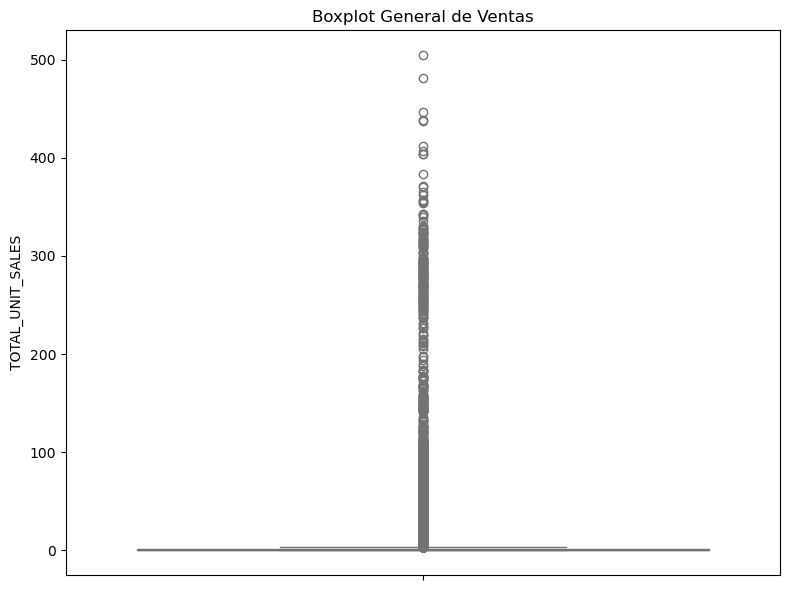

In [40]:
plt.figure(figsize=(8,6))

sns.boxplot(
    y=fact["TOTAL_UNIT_SALES"],
    color="lightgreen"
)

plt.title("Boxplot General de Ventas")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/04_Boxplot_General.png",
    dpi=300
)

plt.show()

In [ ]:
#Boxplot por region

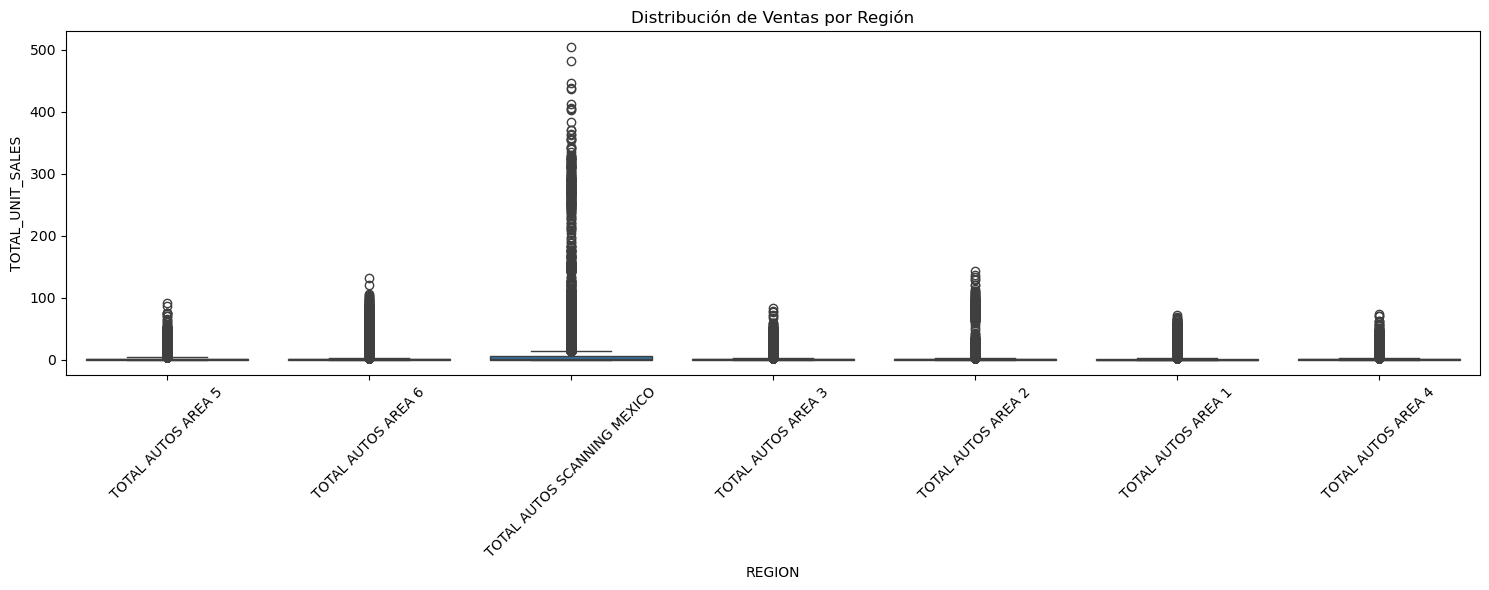

In [41]:
plt.figure(figsize=(15,6))

sns.boxplot(
    data=fact,
    x="REGION",
    y="TOTAL_UNIT_SALES"
)

plt.xticks(rotation=45)

plt.title("Distribución de Ventas por Región")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/05_Boxplot_Region.png",
    dpi=300
)

plt.show()

In [ ]:
# Boxplot por semana

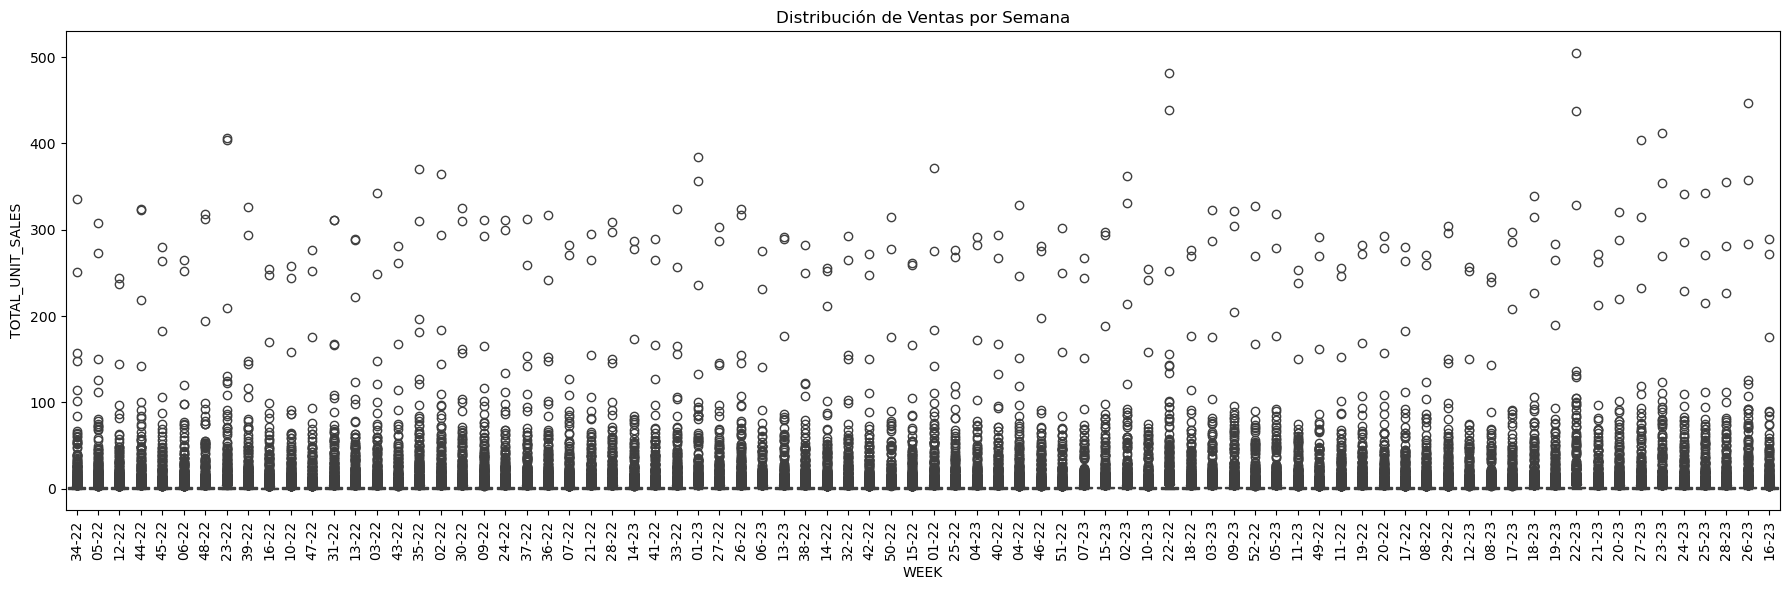

In [42]:
plt.figure(figsize=(18,6))

sns.boxplot(
    data=fact,
    x="WEEK",
    y="TOTAL_UNIT_SALES"
)

plt.xticks(rotation=90)

plt.title("Distribución de Ventas por Semana")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/06_Boxplot_Semana.png",
    dpi=300
)

plt.show()

In [ ]:
# Estadísticas de las ventas

In [43]:
print("Resumen estadístico")

display(

fact["TOTAL_UNIT_SALES"]

.describe()

)

Resumen estadístico


count    122002.000000
mean          3.211097
std          14.496009
min           0.000000
25%           0.063000
50%           0.367000
75%           1.520000
max         504.681000
Name: TOTAL_UNIT_SALES, dtype: float64

In [ ]:
# Detección de Outliers (Método IQR)

In [44]:
Q1 = fact["TOTAL_UNIT_SALES"].quantile(0.25)

Q3 = fact["TOTAL_UNIT_SALES"].quantile(0.75)

IQR = Q3 - Q1

LI = Q1 - 1.5 * IQR

LS = Q3 + 1.5 * IQR

print("Límite inferior:", LI)

print("Límite superior:", LS)

outliers = fact[
    (fact["TOTAL_UNIT_SALES"] < LI) |
    (fact["TOTAL_UNIT_SALES"] > LS)
]

print()

print("Cantidad de Outliers")

print(len(outliers))

Límite inferior: -2.1225
Límite superior: 3.7055000000000002

Cantidad de Outliers
17625


In [ ]:
# Exportar Outliers

In [45]:
outliers.to_csv(
    "Graficas_EDA/Outliers.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo Outliers.csv generado correctamente.")

Archivo Outliers.csv generado correctamente.


In [ ]:
# Comparación datos originales vs Outliers

In [46]:
porcentaje = (len(outliers)/len(fact))*100

print("Registros totales:", len(fact))

print("Outliers:", len(outliers))

print("Porcentaje:", round(porcentaje,2),"%")

Registros totales: 122002
Outliers: 17625
Porcentaje: 14.45 %


In [ ]:
# Distribución después de eliminar Outliers

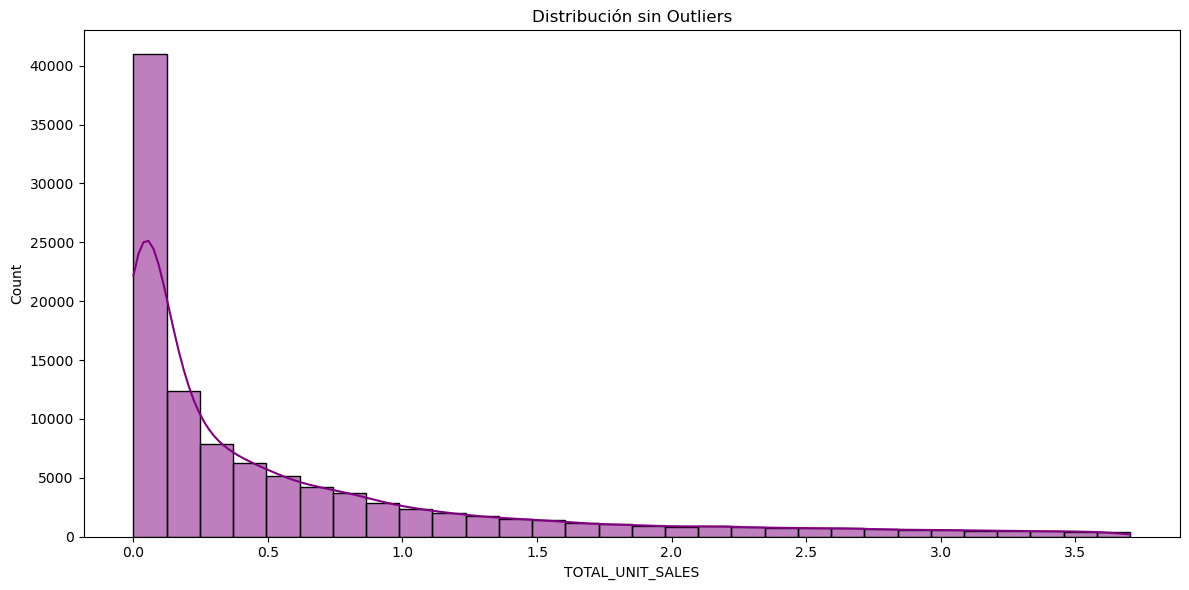

In [47]:
fact_sin = fact[
    (fact["TOTAL_UNIT_SALES"] >= LI) &
    (fact["TOTAL_UNIT_SALES"] <= LS)
]

plt.figure(figsize=(12,6))

sns.histplot(
    fact_sin["TOTAL_UNIT_SALES"],
    bins=30,
    kde=True,
    color="purple"
)

plt.title("Distribución sin Outliers")

plt.tight_layout()

plt.savefig(
    "Graficas_EDA/07_Histograma_Sin_Outliers.png",
    dpi=300
)

plt.show()

In [ ]:
# Exportar estadísticas

In [48]:
estadisticas = fact.describe().T

estadisticas.to_csv(
    "Graficas_EDA/Estadisticas_Descriptivas.csv",
    encoding="utf-8-sig"
)

print("Estadísticas exportadas correctamente.")

Estadísticas exportadas correctamente.


In [ ]:
# Ventas totales por semana

In [49]:
ventas_semana = (

    fact.groupby("WEEK")["TOTAL_VALUE_SALES"]

    .sum()

    .reset_index()

)

display(ventas_semana.head())

,WEEK,TOTAL_VALUE_SALES
0,01-22,151538.922
1,01-23,166309.044
2,02-22,146996.991
3,02-23,155655.882
4,03-22,125351.336


In [ ]:
# Tendencias de ventas

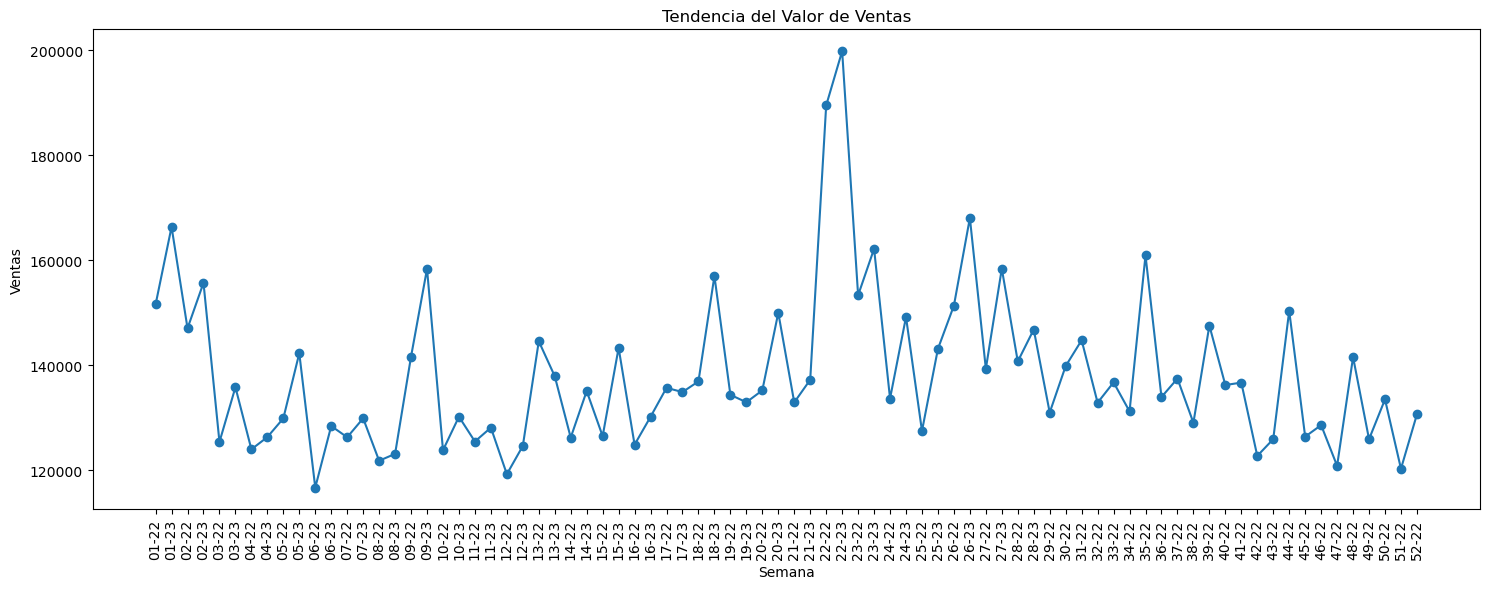

In [50]:
plt.figure(figsize=(15,6))

plt.plot(

    ventas_semana["WEEK"],

    ventas_semana["TOTAL_VALUE_SALES"],

    marker="o"

)

plt.xticks(rotation=90)

plt.title("Tendencia del Valor de Ventas")

plt.xlabel("Semana")

plt.ylabel("Ventas")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/08_Tendencia_Ventas.png",

dpi=300

)

plt.show()

In [ ]:
# Ventas unitarias por semana

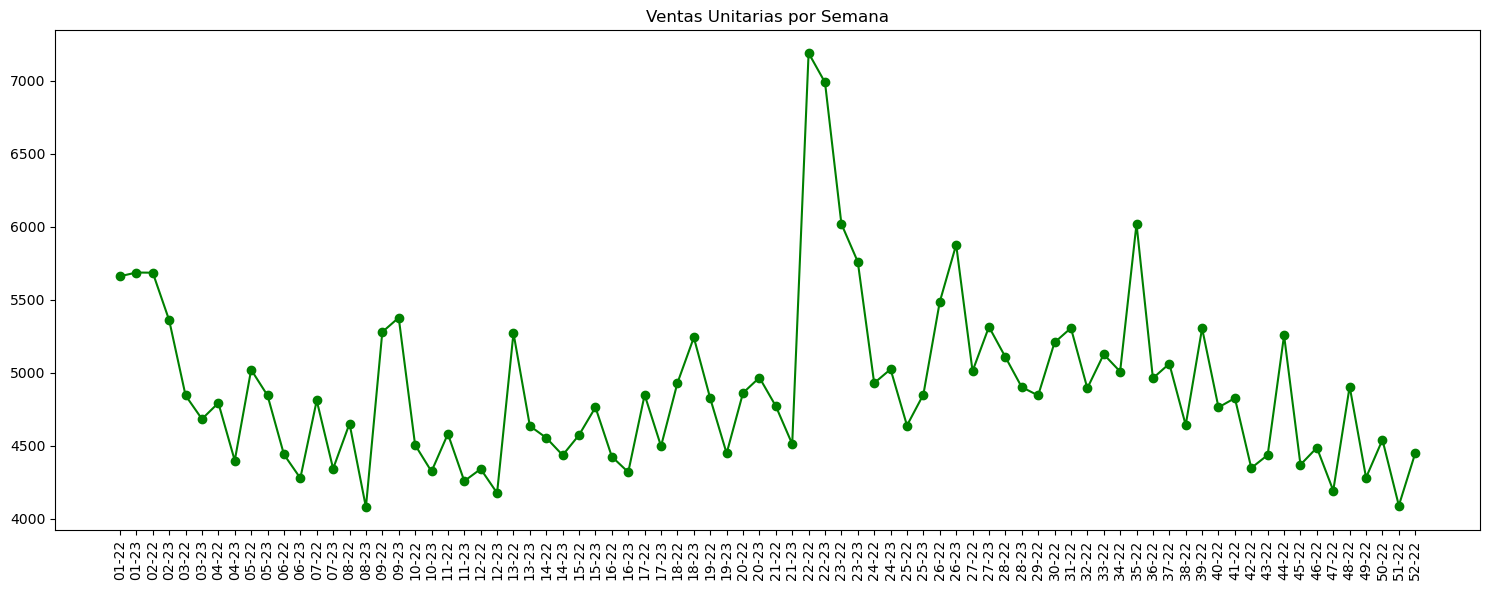

In [51]:
ventas_unidades = (

fact.groupby("WEEK")["TOTAL_UNIT_SALES"]

.sum()

.reset_index()

)

plt.figure(figsize=(15,6))

plt.plot(

ventas_unidades["WEEK"],

ventas_unidades["TOTAL_UNIT_SALES"],

color="green",

marker="o"

)

plt.xticks(rotation=90)

plt.title("Ventas Unitarias por Semana")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/09_Ventas_Unitarias_Semana.png",

dpi=300

)

plt.show()

In [ ]:
# Ventas por región

In [52]:
ventas_region=(

fact.groupby("REGION")["TOTAL_VALUE_SALES"]

.sum()

.sort_values(ascending=False)

)

display(ventas_region)

REGION
TOTAL AUTOS SCANNING MEXICO    5521429.320
TOTAL AUTOS AREA 2             1188796.150
TOTAL AUTOS AREA 5             1153335.538
TOTAL AUTOS AREA 6              983957.571
TOTAL AUTOS AREA 3              803655.337
TOTAL AUTOS AREA 1              714249.979
TOTAL AUTOS AREA 4              677435.998
Name: TOTAL_VALUE_SALES, dtype: float64

In [ ]:
# Gráfico de barras por región

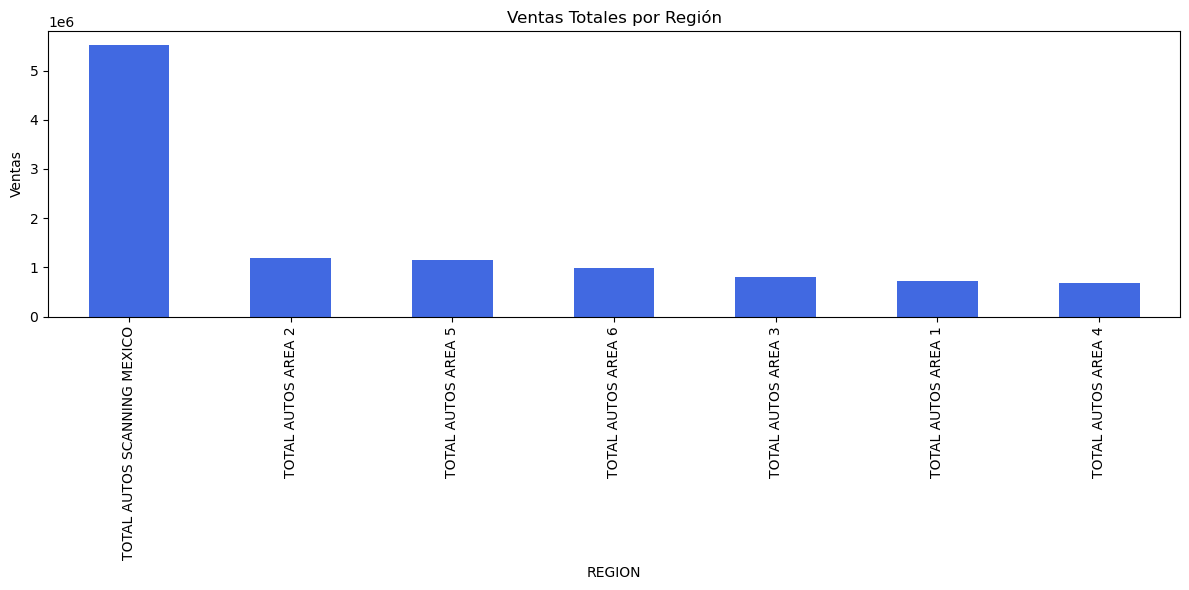

In [53]:
plt.figure(figsize=(12,6))

ventas_region.plot(

kind="bar",

color="royalblue"

)

plt.title("Ventas Totales por Región")

plt.ylabel("Ventas")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/10_Ventas_Region.png",

dpi=300

)

plt.show()

In [ ]:
# Promedio de ventas por región

In [54]:
promedio_region=(

fact.groupby("REGION")["TOTAL_VALUE_SALES"]

.mean()

.sort_values(ascending=False)

)

display(promedio_region)

REGION
TOTAL AUTOS SCANNING MEXICO    263.050468
TOTAL AUTOS AREA 5              71.480356
TOTAL AUTOS AREA 2              64.241889
TOTAL AUTOS AREA 6              58.177589
TOTAL AUTOS AREA 3              48.718195
TOTAL AUTOS AREA 1              45.260122
TOTAL AUTOS AREA 4              39.427075
Name: TOTAL_VALUE_SALES, dtype: float64

In [ ]:
# Grafica de barras horizontales ventas por region

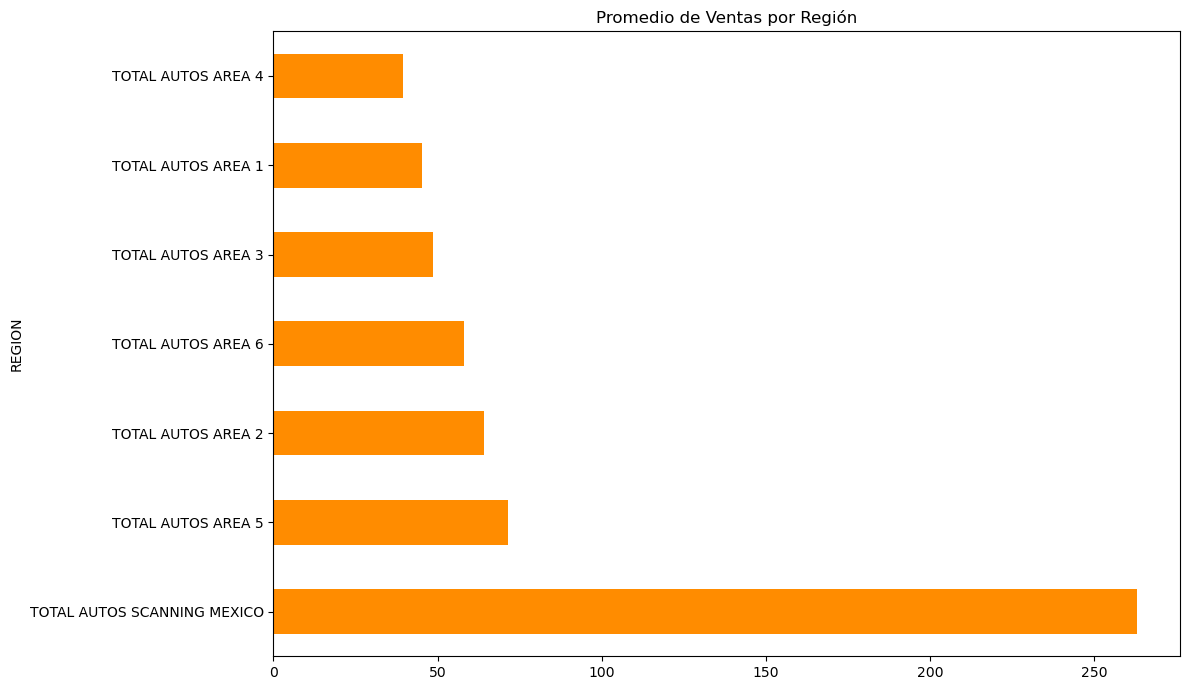

In [55]:
plt.figure(figsize=(12,7))

promedio_region.plot(

kind="barh",

color="darkorange"

)

plt.title("Promedio de Ventas por Región")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/11_Promedio_Region.png",

dpi=300

)

plt.show()

In [ ]:
# Top 20 productos

In [56]:
top20=(

fact.groupby("ITEM_CODE")["TOTAL_UNIT_SALES"]

.sum()

.sort_values(ascending=False)

.head(20)

)

display(top20)

ITEM_CODE
0000075000622    48445.151
0000075000615    46461.839
0000075000639    28334.417
7501025402051    15613.210
7501025405090    14031.408
7501071900143    11129.230
7501025405151    10968.694
7501025450212    10079.695
7501025405212     9667.082
7501058714596     8059.988
7501071900129     8041.870
0741120000005     7171.506
7501058717023     7024.094
7891035040276     6988.174
7501025401801     6166.924
7501025405106     5624.462
7501071905551     5384.309
7501025401795     5176.230
7501058717030     5046.584
7501025411992     4868.804
Name: TOTAL_UNIT_SALES, dtype: float64

In [ ]:
# Grafico de los 20 productos top

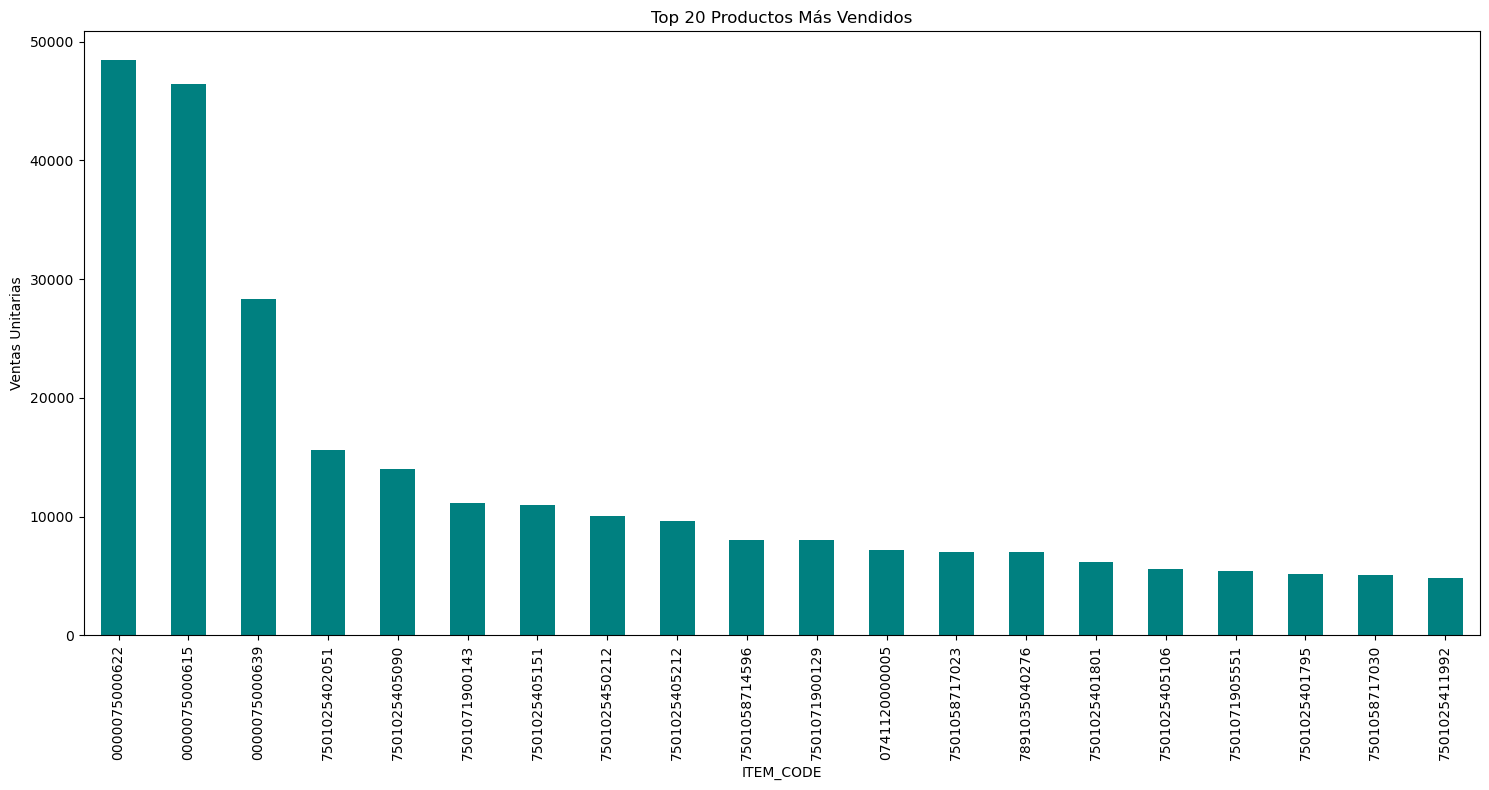

In [57]:
plt.figure(figsize=(15,8))

top20.plot(

kind="bar",

color="teal"

)

plt.title("Top 20 Productos Más Vendidos")

plt.ylabel("Ventas Unitarias")

plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(

"Graficas_EDA/12_Top20_Productos.png",

dpi=300

)

plt.show()

In [ ]:
# Top 10 semanas

In [58]:
top10=(

ventas_semana

.sort_values(

by="TOTAL_VALUE_SALES",

ascending=False

)

.head(10)

)

display(top10)

,WEEK,TOTAL_VALUE_SALES
43,22-23,199783.534
42,22-22,189443.349
51,26-23,168005.338
1,01-23,166309.044
45,23-23,162140.458
62,35-22,160891.034
53,27-23,158351.321
17,09-23,158318.691
35,18-23,156961.164
3,02-23,155655.882


In [ ]:
# Gráfico de las 10 semanas top

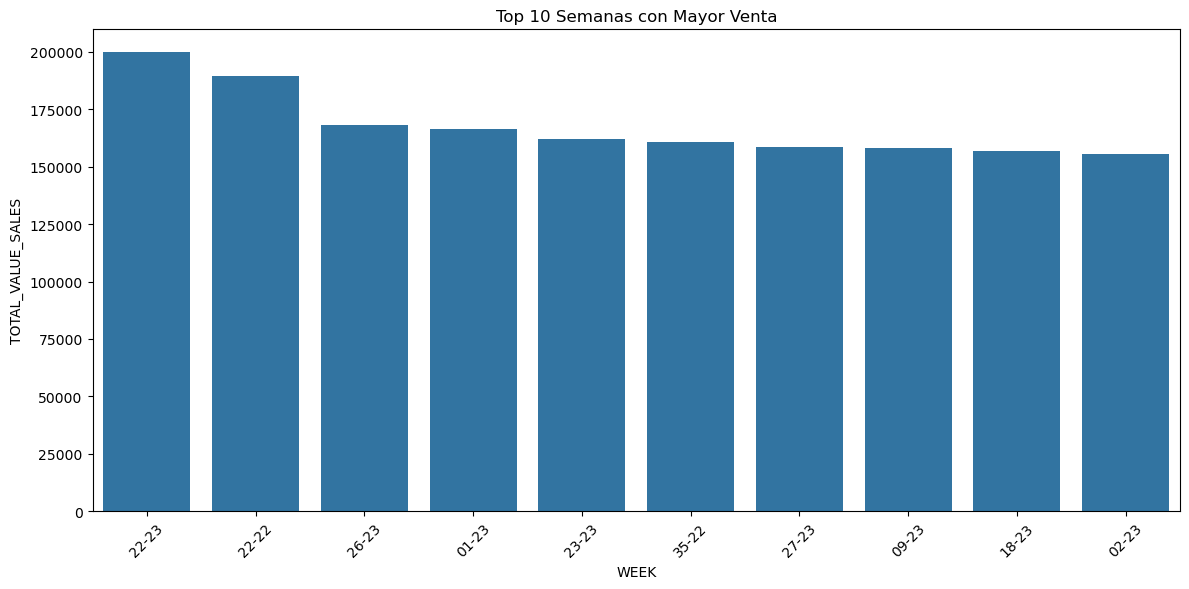

In [59]:
plt.figure(figsize=(12,6))

sns.barplot(

data=top10,

x="WEEK",

y="TOTAL_VALUE_SALES"

)

plt.xticks(rotation=45)

plt.title("Top 10 Semanas con Mayor Venta")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/13_Top10_Semanas.png",

dpi=300

)

plt.show()

In [ ]:
# Scatter Plot

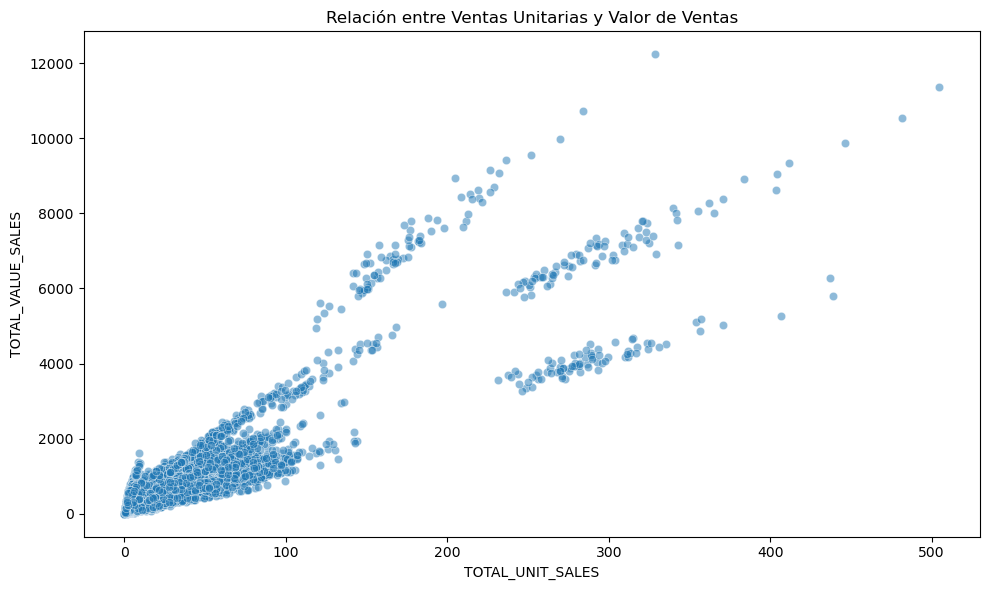

In [60]:
plt.figure(figsize=(10,6))

sns.scatterplot(

data=fact,

x="TOTAL_UNIT_SALES",

y="TOTAL_VALUE_SALES",

alpha=0.5

)

plt.title("Relación entre Ventas Unitarias y Valor de Ventas")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/14_Scatter.png",

dpi=300

)

plt.show()

In [ ]:
# Matriz de correlación

In [61]:
correlacion=fact[[

"TOTAL_UNIT_SALES",

"TOTAL_VALUE_SALES",

"TOTAL_UNIT_AVG_WEEKLY_SALES"

]].corr()

display(correlacion)


,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
TOTAL_UNIT_SALES,1.000000,0.916252,0.426035
TOTAL_VALUE_SALES,0.916252,1.000000,0.367367
TOTAL_UNIT_AVG_WEEKLY_SALES,0.426035,0.367367,1.000000


In [ ]:
# HeatMap

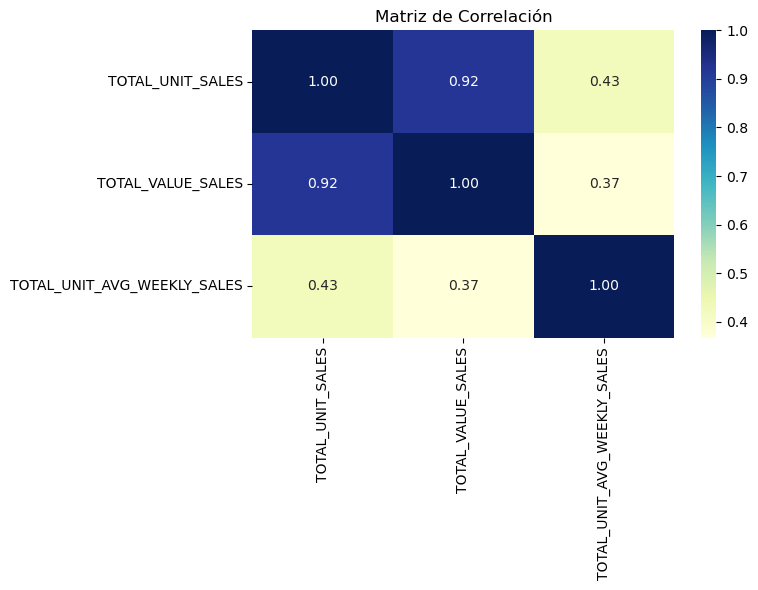

In [62]:
plt.figure(figsize=(8,6))

sns.heatmap(

correlacion,

annot=True,

cmap="YlGnBu",

fmt=".2f"

)

plt.title("Matriz de Correlación")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/15_Heatmap_Correlacion.png",

dpi=300

)

plt.show()

In [ ]:
# Exportar tablas de resultados

In [63]:
ventas_region.to_csv(

"Graficas_EDA/Ventas_por_Region.csv",

encoding="utf-8-sig"

)

top20.to_csv(

"Graficas_EDA/Top20_Productos.csv",

encoding="utf-8-sig"

)

ventas_semana.to_csv(

"Graficas_EDA/Ventas_por_Semana.csv",

index=False,

encoding="utf-8-sig"

)

correlacion.to_csv(

"Graficas_EDA/Matriz_Correlacion.csv",

encoding="utf-8-sig"

)

print("Archivos exportados correctamente.")

Archivos exportados correctamente.


In [ ]:
#Percentiles

In [64]:
print("Percentiles")

percentiles = fact["TOTAL_VALUE_SALES"].quantile(

[0.10,
0.25,
0.50,
0.75,
0.90,
0.95,
0.99]

)

display(percentiles)

Percentiles


0.10       0.2750
0.25       2.6620
0.50      16.8120
0.75      62.9615
0.90     177.9261
0.95     356.0437
0.99    1162.0060
Name: TOTAL_VALUE_SALES, dtype: float64

In [ ]:
# Segmentación de Ventas

In [65]:
Q1 = fact["TOTAL_VALUE_SALES"].quantile(.25)
Q2 = fact["TOTAL_VALUE_SALES"].quantile(.50)
Q3 = fact["TOTAL_VALUE_SALES"].quantile(.75)

def segmento(valor):

    if valor <= Q1:
        return "Bajas"

    elif valor <= Q2:
        return "Medias"

    elif valor <= Q3:
        return "Altas"

    else:
        return "Muy Altas"

fact["SEGMENTO"] = fact["TOTAL_VALUE_SALES"].apply(segmento)

display(

fact["SEGMENTO"]

.value_counts()

)

SEGMENTO
Bajas        30502
Muy Altas    30501
Medias       30500
Altas        30499
Name: count, dtype: int64

In [ ]:
# Gráfico de Segmentación

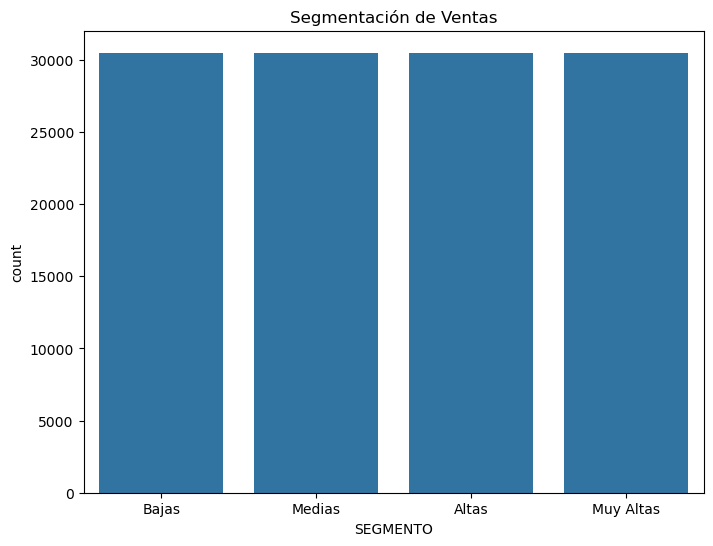

In [66]:
plt.figure(figsize=(8,6))

sns.countplot(

data=fact,

x="SEGMENTO",

order=["Bajas","Medias","Altas","Muy Altas"]

)

plt.title("Segmentación de Ventas")

plt.savefig(

"Graficas_EDA/16_Segmentacion.png",

dpi=300

)

plt.show()

In [ ]:
# Curva de Pareto

In [67]:
pareto = (

fact.groupby("ITEM_CODE")["TOTAL_VALUE_SALES"]

.sum()

.sort_values(ascending=False)

)

pareto = pareto.reset_index()

pareto["ACUMULADO"] = pareto["TOTAL_VALUE_SALES"].cumsum()

pareto["PORCENTAJE"] = (

100 *

pareto["ACUMULADO"] /

pareto["TOTAL_VALUE_SALES"].sum()

)

display(pareto.head())

,ITEM_CODE,TOTAL_VALUE_SALES,ACUMULADO,PORCENTAJE
0,0000075000639,1146849.632,1146849.632,10.385440
1,0000075000622,1139233.787,2286083.419,20.701915
2,0000075000615,658584.568,2944667.987,26.665810
3,7501025402051,491075.232,3435743.219,31.112803
4,7501071900143,399994.779,3835737.998,34.735006


In [ ]:
# Gráfico de Pareto

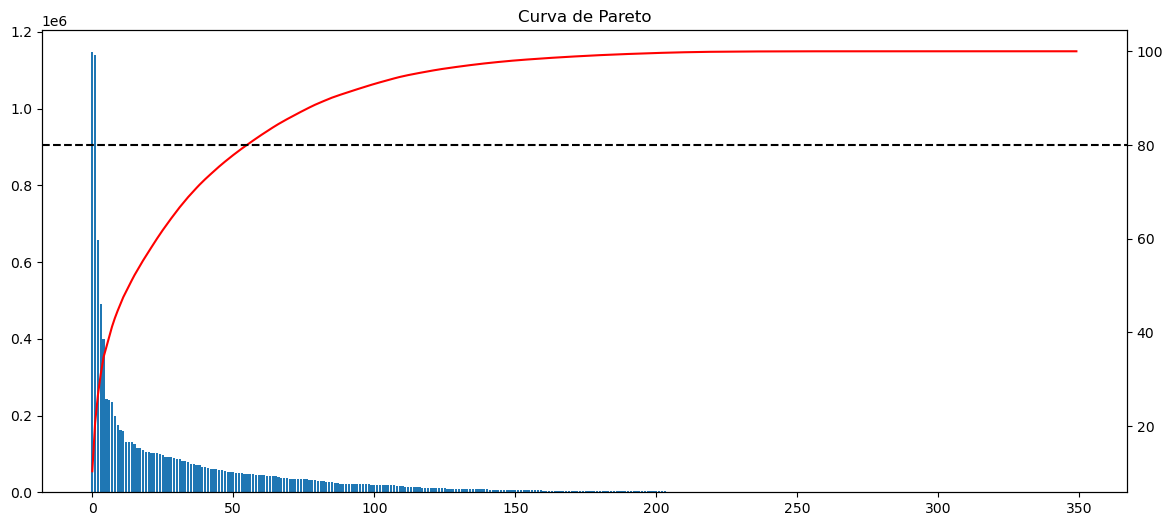

In [68]:
fig, ax1 = plt.subplots(figsize=(14,6))

ax1.bar(

pareto.index,

pareto["TOTAL_VALUE_SALES"]

)

ax2 = ax1.twinx()

ax2.plot(

pareto.index,

pareto["PORCENTAJE"],

color="red"

)

ax2.axhline(

80,

linestyle="--",

color="black"

)

plt.title("Curva de Pareto")

plt.savefig(

"Graficas_EDA/17_Pareto.png",

dpi=300

)

plt.show()

In [ ]:
# Ventas promedio por semana

In [69]:
promedio = (

fact.groupby("WEEK")

["TOTAL_VALUE_SALES"]

.mean()

.reset_index()

)

display(promedio.head())

,WEEK,TOTAL_VALUE_SALES
0,01-22,95.008729
1,01-23,113.521532
2,02-22,91.245804
3,02-23,105.888355
4,03-22,78.590179


In [ ]:
# Gráfico de promedio semanal

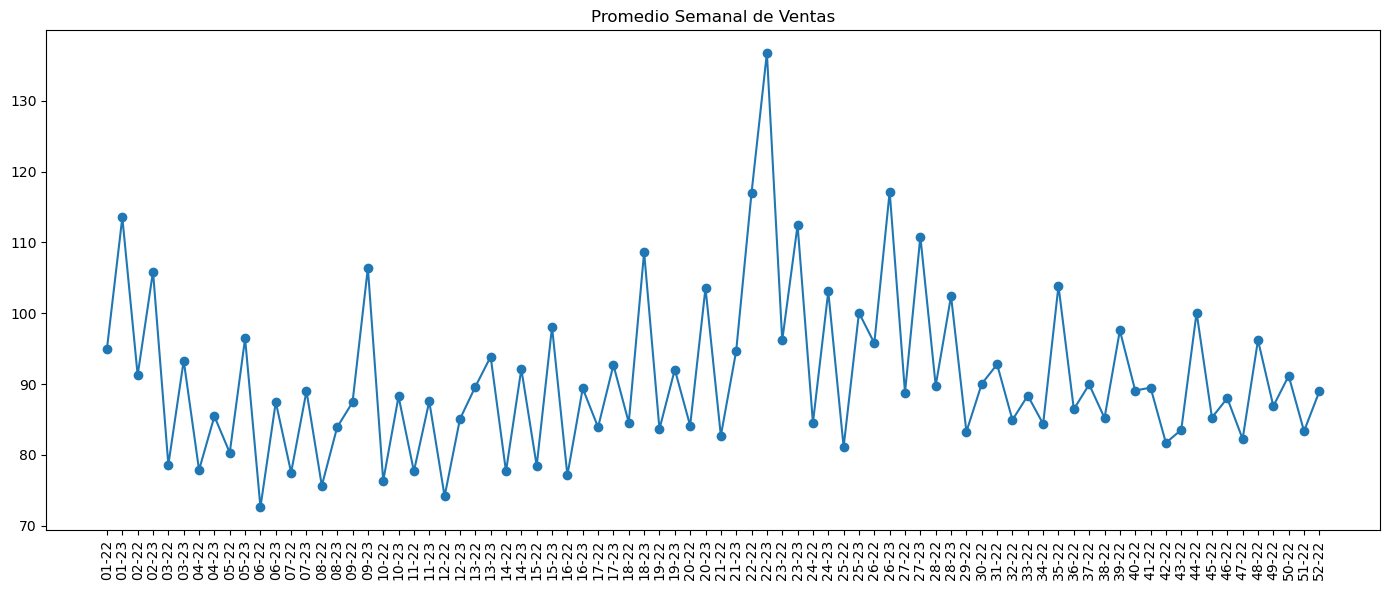

In [70]:
plt.figure(figsize=(14,6))

plt.plot(

promedio["WEEK"],

promedio["TOTAL_VALUE_SALES"],

marker="o"

)

plt.xticks(rotation=90)

plt.title("Promedio Semanal de Ventas")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/18_Promedio_Semanal.png",

dpi=300

)

plt.show()

In [ ]:
# Heatman Región vs Semana

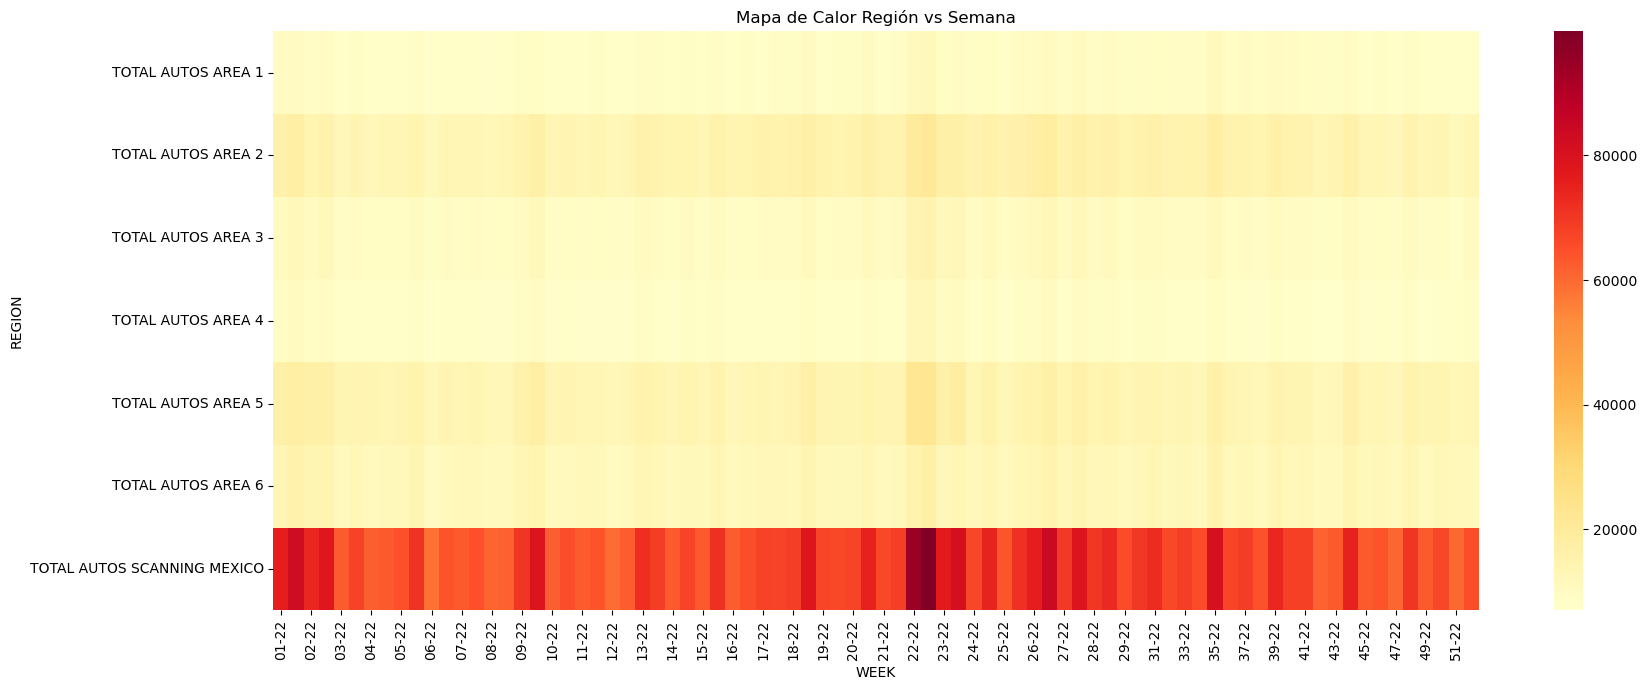

In [71]:
tabla = pd.pivot_table(

fact,

values="TOTAL_VALUE_SALES",

index="REGION",

columns="WEEK",

aggfunc="sum"

)

plt.figure(figsize=(18,7))

sns.heatmap(

tabla,

cmap="YlOrRd"

)

plt.title("Mapa de Calor Región vs Semana")

plt.tight_layout()

plt.savefig(

"Graficas_EDA/19_Heatmap_Region_Semana.png",

dpi=300

)

plt.show()

In [ ]:
# Ranking de regiones

In [72]:
ranking_region = (

fact.groupby("REGION")

["TOTAL_VALUE_SALES"]

.sum()

.rank(

ascending=False,

method="dense"

)

)

display(ranking_region)

REGION
TOTAL AUTOS AREA 1             6.0
TOTAL AUTOS AREA 2             2.0
TOTAL AUTOS AREA 3             5.0
TOTAL AUTOS AREA 4             7.0
TOTAL AUTOS AREA 5             3.0
TOTAL AUTOS AREA 6             4.0
TOTAL AUTOS SCANNING MEXICO    1.0
Name: TOTAL_VALUE_SALES, dtype: float64

In [ ]:
#Rankin de semanas

In [73]:
ranking_semana = (

fact.groupby("WEEK")

["TOTAL_VALUE_SALES"]

.sum()

.rank(

ascending=False,

method="dense"

)

)

display(ranking_semana)

WEEK
01-22    12.0
01-23     4.0
02-22    18.0
02-23    10.0
03-22    69.0
         ... 
48-22    26.0
49-22    67.0
50-22    45.0
51-22    78.0
52-22    51.0
Name: TOTAL_VALUE_SALES, Length: 80, dtype: float64

In [ ]:
# Detección de anomalías (Z-Score)

In [79]:
fact["ZSCORE"] = zscore(

fact["TOTAL_VALUE_SALES"]

)

anomalias = fact[

abs(fact["ZSCORE"]) > 3

]

print(

"Cantidad de anomalías:",

len(anomalias)

)

display(

anomalias.head()

)

Cantidad de anomalías: 1278


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION,SEGMENTO,ZSCORE
67,05-22,7501071900143,56.046,2089.002,22.057,TOTAL AUTOS SCANNING MEXICO,Muy Altas,5.706134
179,45-22,7501025450212,56.521,1368.271,132.058,TOTAL AUTOS SCANNING MEXICO,Muy Altas,3.648285
180,45-22,0000075000622,263.552,6116.936,96.575,TOTAL AUTOS SCANNING MEXICO,Muy Altas,17.206793
182,45-22,0000075000639,182.755,7235.207,60.315,TOTAL AUTOS SCANNING MEXICO,Muy Altas,20.399708
184,45-22,0000075000615,279.412,3947.028,93.355,TOTAL AUTOS SCANNING MEXICO,Muy Altas,11.011217


In [ ]:
# Histograma Z-Score

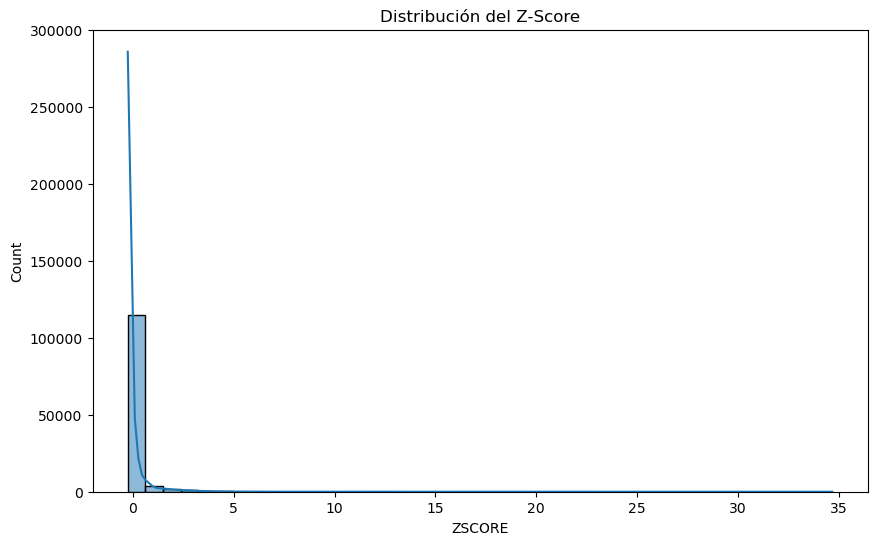

In [97]:
plt.figure(figsize=(10,6))

sns.histplot(

fact["ZSCORE"],

bins=40,

kde=True

)

plt.title("Distribución del Z-Score")

plt.savefig(

"Graficas_EDA/20_ZScore.png",

dpi=300

)

plt.show()

In [ ]:
# Tabla resumen para Dashboard

In [75]:
dashboard = fact.groupby(

["REGION","WEEK"]

).agg(

Ventas_Valor=("TOTAL_VALUE_SALES","sum"),

Ventas_Unidades=("TOTAL_UNIT_SALES","sum"),

Promedio=("TOTAL_UNIT_AVG_WEEKLY_SALES","mean")

).reset_index()

display(dashboard.head())

,REGION,WEEK,Ventas_Valor,Ventas_Unidades,Promedio
0,TOTAL AUTOS AREA 1,01-22,9708.353,373.381,10.269446
1,TOTAL AUTOS AREA 1,01-23,10074.922,347.964,9.546704
2,TOTAL AUTOS AREA 1,02-22,9079.403,355.540,9.727038
3,TOTAL AUTOS AREA 1,02-23,9604.200,337.980,9.265162
4,TOTAL AUTOS AREA 1,03-22,8345.472,328.907,8.466910


In [ ]:
#Exportar archivos

In [80]:
dashboard.to_csv(

"Graficas_EDA/Dashboard_Data.csv",

index=False,

encoding="utf-8-sig"

)

pareto.to_csv(

"Graficas_EDA/Pareto.csv",

index=False,

encoding="utf-8-sig"

)

anomalias.to_csv(

"Graficas_EDA/Anomalias.csv",

index=False,

encoding="utf-8-sig"

)

print("Archivos exportados correctamente.")

Archivos exportados correctamente.


In [ ]:
# Cálculo de KPIs

In [81]:
ventas_totales = fact["TOTAL_VALUE_SALES"].sum()

ventas_unitarias = fact["TOTAL_UNIT_SALES"].sum()

venta_promedio = fact["TOTAL_VALUE_SALES"].mean()

venta_maxima = fact["TOTAL_VALUE_SALES"].max()

venta_minima = fact["TOTAL_VALUE_SALES"].min()

numero_productos = fact["ITEM_CODE"].nunique()

numero_regiones = fact["REGION"].nunique()

numero_semanas = fact["WEEK"].nunique()

kpis = pd.DataFrame({

"KPI":[

"Ventas Totales",

"Ventas Unitarias",

"Venta Promedio",

"Venta Máxima",

"Venta Mínima",

"Número de Productos",

"Número de Regiones",

"Número de Semanas"

],

"Valor":[

ventas_totales,

ventas_unitarias,

venta_promedio,

venta_maxima,

venta_minima,

numero_productos,

numero_regiones,

numero_semanas

]

})

display(kpis)

,KPI,Valor
0,Ventas Totales,1.104286e+07
1,Ventas Unitarias,3.917602e+05
2,Venta Promedio,9.051376e+01
3,Venta Máxima,1.223676e+04
4,Venta Mínima,1.000000e-03
5,Número de Productos,3.500000e+02
6,Número de Regiones,7.000000e+00
7,Número de Semanas,8.000000e+01


In [ ]:
# EXportar KPIs

In [87]:
kpis.to_csv(

"Graficas_EDA/Resultados_Finales/KPIs.csv",

index=False,

encoding="utf-8-sig"

)

print("KPIs exportados.")

KPIs exportados.


In [ ]:
# Dashboard ejecutivo

In [84]:
dashboard = fact.groupby(

["REGION"]

).agg(

Ventas=("TOTAL_VALUE_SALES","sum"),

Unidades=("TOTAL_UNIT_SALES","sum"),

Promedio=("TOTAL_UNIT_AVG_WEEKLY_SALES","mean")

).reset_index()

display(dashboard)

,REGION,Ventas,Unidades,Promedio
0,TOTAL AUTOS AREA 1,714249.979,25791.933,8.156537
1,TOTAL AUTOS AREA 2,1188796.150,45319.916,9.756997
2,TOTAL AUTOS AREA 3,803655.337,25896.054,10.992248
3,TOTAL AUTOS AREA 4,677435.998,24020.149,9.000718
4,TOTAL AUTOS AREA 5,1153335.538,36266.900,10.853990
5,TOTAL AUTOS AREA 6,983957.571,38585.222,10.851882
6,TOTAL AUTOS SCANNING MEXICO,5521429.320,195880.054,10.876203


In [ ]:
# Exportar Dashboard

In [90]:
dashboard.to_csv(

"Graficas_EDA/Resultados_Finales/Dashboard.csv",

index=False,

encoding="utf-8-sig"

)

In [ ]:
# Dataset Limpio

In [91]:
fact_limpio = fact.copy()

fact_limpio = fact_limpio.drop_duplicates()

fact_limpio = fact_limpio.fillna(0)

fact_limpio.to_csv(

"Graficas_EDA/Resultados_Finales/FACT_SALES_LIMPIO.csv",

index=False,

encoding="utf-8-sig"

)

print("Dataset limpio generado.")

Dataset limpio generado.


In [ ]:
# Diccionario de Datos

In [92]:
diccionario = pd.DataFrame({

"Variable":[

"WEEK",

"ITEM_CODE",

"TOTAL_UNIT_SALES",

"TOTAL_VALUE_SALES",

"TOTAL_UNIT_AVG_WEEKLY_SALES",

"REGION"

],

"Descripción":[

"Semana de la venta",

"Código del producto",

"Cantidad de unidades vendidas",

"Valor monetario de las ventas",

"Promedio semanal de unidades",

"Región donde ocurrió la venta"

]

})

display(diccionario)

,Variable,Descripción
0,WEEK,Semana de la venta
1,ITEM_CODE,Código del producto
2,TOTAL_UNIT_SALES,Cantidad de unidades vendidas
3,TOTAL_VALUE_SALES,Valor monetario de las ventas
4,TOTAL_UNIT_AVG_WEEKLY_SALES,Promedio semanal de unidades
5,REGION,Región donde ocurrió la venta


In [ ]:
# Exportar Diccionario

In [93]:
diccionario.to_csv(

"Graficas_EDA/Resultados_Finales/Diccionario_Datos.csv",

index=False,

encoding="utf-8-sig"

)

In [ ]:
# Resumen 

In [94]:
print("="*60)
print("RESUMEN")
print("="*60)

print("Ventas Totales:", ventas_totales)

print("Ventas Unitarias:", ventas_unitarias)

print("Promedio de Venta:", round(venta_promedio,2))

print("Productos Analizados:", numero_productos)

print("Regiones:", numero_regiones)

print("Semanas:", numero_semanas)

RESUMEN
Ventas Totales: 11042859.893000001
Ventas Unitarias: 391760.228
Promedio de Venta: 90.51
Productos Analizados: 350
Regiones: 7
Semanas: 80


In [ ]:
# Preparacion para Power BI

In [96]:
powerbi = fact.groupby(

["REGION","WEEK"]

).agg(

Ventas=("TOTAL_VALUE_SALES","sum"),

Unidades=("TOTAL_UNIT_SALES","sum"),

Promedio=("TOTAL_UNIT_AVG_WEEKLY_SALES","mean")

).reset_index()

powerbi.to_csv(

"Graficas_EDA/Resultados_Finales/PowerBI.csv",

index=False,

encoding="utf-8-sig"

)

print("Archivo preparado para Power BI.")

Archivo preparado para Power BI.
